In [1]:
# Parameters
BATCH_MODE = "true"

print(f"BATCH_MODE = {BATCH_MODE}")

BATCH_MODE = true


# App-3 : Nurse Scheduling (Planification des horaires infirmiers)

**Navigation** : [<< App-2 GraphColoring](App-2-GraphColoring.ipynb) | [Index](../README.md) | [App-4 JobShopScheduling >>](App-4-JobShopScheduling.ipynb)

## Objectifs d'apprentissage

A la fin de ce notebook, vous saurez :
1. **Modeliser** le Nurse Rostering Problem (NRP) comme un problème de satisfaction de contraintes
2. **Distinguer** contraintes dures (obligatoires) et souples (préférences)
3. **Implementer** un modèle CP-SAT complet avec OR-Tools
4. **Optimiser** un planning en minimisant les penalites (equilibre de charge, préférences)
5. **Visualiser** et analyser la qualite d'un planning infirmier

### Prerequis
- Python 3.10+
- CSP-3 (Advanced) : programmation par contraintes avec OR-Tools
- Notions de base sur les problemes d'optimisation combinatoire

### Duree estimee : 60 minutes

## Hommage a un travail etudiant

Ce notebook distille le projet **Sujet 1 -- Nurse Rostering Problem** du cours EPITA SCIA *Programmation par Contraintes* 2025, realise par **Leo Lopes** ([Leo Lopes](https://github.com/Lazyyx)) et **Yahya Ahachim** ([Yahya Ahachim](https://github.com/qghrjf646)) : [repertoire source](https://github.com/jsboigeEpita/2025-Epita-Programmation-par-Contraintes/tree/main/Nurse_Rostering_Problem), commit `4394d10`, licence non specifiee au niveau du sous-projet (utilisee avec attribution, conformement a la confirmation user 2026-09-15 -- le depot parent ne porte pas de LICENSE globale).

Le projet etudiant articule deja l'essentiel de ce que ce notebook pedagogique re-prend :

- la **structure du modele CP-SAT** (variables booleennes $x_{n,d,s}$, couverture exacte par shift, unicite par jour, repos apres nuit, charge max par semaine) ;
- la **fonction objectif ponderee** distinguant equilibre de charge et respect des preferences ;
- le **passage a l'echelle** (jusqu'a 15 infirmiers sur 28 jours dans leur `complete_solver.py`) qui sert ici de demonstration industrielle.

Ce qui est *ajoute* dans ce notebook par rapport au projet source :

1. la decomposition progressive entre **contraintes dures seules** (Section 3) puis **contraintes dures + souples** (Section 4), pour faire voir comment la solution evolue quand on ajoute l'objectif ;
2. la **solution callback** et la **courbe de convergence** (Section 5) -- le projet source utilise un solve-and-print, pas un suivi temporel ;
3. la **visualisation heatmap cote a cote** (Section 5) qui rend visible la difference entre planning faisable et planning optimise ;
4. les **trois exemples guides et trois exercices** (Section 6) sur les variations realistes du NRP (consecutifs, priorites, temps partiels).

L'enrichissement preserve l'integrite du modele CP-SAT du projet etudiant : aucune equation, aucune constante, aucun encodage de variable n'a ete modifie. Les differences sont dans la *forme pedagogique* (progression, visualisation, exercices), pas dans le *fond algorithmique*.

***

## 1. Introduction (~5 min)

Le **Nurse Rostering Problem** (NRP) consiste a affecter des équipes (shifts) a un ensemble d'infirmiers sur un horizon de planification, en respectant la reglementation du travail, les besoins en personnel et les préférences individuelles.

### Pourquoi ce problème est important

| Aspect | Impact |
|--------|--------|
| **Sante** | Un planning mal concu entraine fatigue, erreurs medicales, burnout |
| **Reglementation** | Les lois du travail imposent des contraintes strictes (repos, duree max) |
| **Equite** | Les infirmiers doivent percevoir la repartition comme juste |
| **Complexite** | NP-hard des que l'on depasse quelques infirmiers et quelques jours |
| **Volume** | Des milliers d'hopitaux doivent resoudre ce problème chaque mois |

### Approche

Nous allons progresser en trois étapes :
1. **Modèle de base** : 5 infirmiers, 7 jours, contraintes dures uniquement
2. **Optimisation** : ajout de contraintes souples (equilibre, préférences) avec fonction objectif
3. **Passage a l'echelle** : 15 infirmiers, 28 jours, paramètres avances du solveur

### Installation et imports

Nous utilisons **OR-Tools** de Google, la bibliotheque de reference pour la programmation par contraintes et l'optimisation. Le solveur CP-SAT est particulierement adapte aux problemes de planification.

In [2]:
# Installation si necessaire
# !pip install ortools matplotlib numpy

import sys
import time
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from ortools.sat.python import cp_model

# Helpers partages de la serie Search
sys.path.insert(0, '..')
from search_helpers import benchmark_table

print(f"OR-Tools version : {cp_model.__name__}")
print("Imports OK")

OR-Tools version : ortools.sat.python.cp_model
Imports OK


### Lecture du résultat

La sortie « OR-Tools version : ortools.sat.python.cp_model » suivie de « Imports OK » confirme que l'environnement est prêt : le solveur CP-SAT est importé via `ortools.sat.python.cp_model` et aucune erreur d'import n'est levée. Toutes les cellules suivantes peuvent donc utiliser `cp_model` directement, sans installation supplémentaire. Aucun modèle n'est encore construit à ce stade : cette cellule ne fait que valider la chaîne d'import de la bibliothèque cible avant la définition des données, ce qui évite des erreurs tardives difficiles à diagnostiquer en plein milieu du notebook.

***

## 2. Formulation du problème (~8 min)

### Données du problème

Nous commencons par un cas de taille modeste pour bien comprendre la modelisation.

| Paramètre | Valeur |
|-----------|--------|
| Infirmiers | 5 (Alice, Bob, Claire, David, Emma) |
| Jours | 7 (lundi a dimanche) |
| Équipes (shifts) | 3 : Matin (M), Après-midi (A), Nuit (N) |
| Besoin par shift | Exactement 1 infirmier par shift par jour |

### Variables de decision

Pour chaque triplet (infirmier $n$, jour $d$, shift $s$), on définit une variable booleenne :

$$x_{n,d,s} \in \{0, 1\}$$

ou $x_{n,d,s} = 1$ signifie que l'infirmier $n$ travaille le shift $s$ le jour $d$.

**Taille de l'espace** : $2^{5 \times 7 \times 3} = 2^{105} \approx 4 \times 10^{31}$ combinaisons possibles.

### Contraintes dures (obligatoires)

| # | Contrainte | Formulation |
|---|------------|-------------|
| C1 | **Couverture** | Chaque shift de chaque jour doit etre assure par exactement 1 infirmier : $\sum_n x_{n,d,s} = 1$ |
| C2 | **Unicite** | Un infirmier ne peut pas travailler 2 shifts le même jour : $\sum_s x_{n,d,s} \leq 1$ |
| C3 | **Repos** | Pas de shift Matin après un shift Nuit (repos obligatoire) |
| C4 | **Charge max** | Maximum 5 shifts par semaine par infirmier : $\sum_{d,s} x_{n,d,s} \leq 5$ |

### Contraintes souples (a optimiser)

| # | Contrainte | Objectif |
|---|------------|----------|
| S1 | **Equilibre de charge** | Minimiser l'ecart de nombre de shifts entre infirmiers |
| S2 | **Préférences** | Respecter les préférences individuelles (ex : pas de weekend) |

### Definition des données

Definissons les constantes du problème et les préférences des infirmiers.

In [3]:
# --- Donnees du probleme ---

# Infirmiers
nurses = ['Alice', 'Bob', 'Claire', 'David', 'Emma']
num_nurses = len(nurses)

# Jours de la semaine
days = ['Lun', 'Mar', 'Mer', 'Jeu', 'Ven', 'Sam', 'Dim']
num_days = len(days)

# Shifts (equipes)
shifts = ['Matin', 'Apres-midi', 'Nuit']
num_shifts = len(shifts)

# Indices pour faciliter la modelisation
MATIN = 0
APRES_MIDI = 1
NUIT = 2

# Jours du weekend
weekend_days = [5, 6]  # Samedi, Dimanche

# Preferences des infirmiers (jours/shifts non desires)
# Format : {nurse_index: [(day_index, shift_index), ...]}
preferences = {
    0: [(5, MATIN), (5, APRES_MIDI), (6, MATIN), (6, APRES_MIDI)],  # Alice : pas de weekend jour
    1: [(0, NUIT), (1, NUIT), (2, NUIT)],  # Bob : pas de nuits en debut de semaine
    2: [],  # Claire : pas de preference particuliere
    3: [(4, MATIN), (4, APRES_MIDI), (4, NUIT)],  # David : prefere ne pas travailler vendredi
    4: [(6, NUIT)],  # Emma : pas de nuit le dimanche
}

# Penalite pour chaque preference non respectee
preference_penalty = 2

# Besoin par shift par jour (1 infirmier par shift)
demand = 1

# Charge maximale par semaine
max_shifts_per_week = 5

# Affichage
print("Donnees du probleme")
print("=" * 50)
print(f"Infirmiers       : {num_nurses} ({', '.join(nurses)})")
print(f"Jours            : {num_days} ({', '.join(days)})")
print(f"Shifts/jour      : {num_shifts} ({', '.join(shifts)})")
print(f"Slots a couvrir  : {num_days * num_shifts}")
print(f"Variables bool   : {num_nurses * num_days * num_shifts}")
print(f"Espace brut      : 2^{num_nurses * num_days * num_shifts}")
print(f"Charge max/sem   : {max_shifts_per_week} shifts")
print(f"\nPreferences :")
for n in range(num_nurses):
    prefs = preferences[n]
    if prefs:
        pref_str = ', '.join(f"{days[d]}-{shifts[s]}" for d, s in prefs)
        print(f"  {nurses[n]:>8} : eviter {pref_str}")
    else:
        print(f"  {nurses[n]:>8} : aucune preference")

Donnees du probleme
Infirmiers       : 5 (Alice, Bob, Claire, David, Emma)
Jours            : 7 (Lun, Mar, Mer, Jeu, Ven, Sam, Dim)
Shifts/jour      : 3 (Matin, Apres-midi, Nuit)
Slots a couvrir  : 21
Variables bool   : 105
Espace brut      : 2^105
Charge max/sem   : 5 shifts

Preferences :
     Alice : eviter Sam-Matin, Sam-Apres-midi, Dim-Matin, Dim-Apres-midi
       Bob : eviter Lun-Nuit, Mar-Nuit, Mer-Nuit
    Claire : aucune preference
     David : eviter Ven-Matin, Ven-Apres-midi, Ven-Nuit
      Emma : eviter Dim-Nuit


### Lecture du résultat

La sortie détaille l'instance : 5 infirmiers (Alice, Bob, Claire, David, Emma), 7 jours, 3 shifts/jour, soit « Slots a couvrir : 21 » et « Variables bool : 105 » (espace brut « 2^105 »), avec une charge max de 5 shifts/semaine. Le bloc « Preferences » décompte 11 préférences au total (4 pour Alice, 3 pour Bob, aucune pour Claire, 3 pour David, 1 pour Emma) : c'est ce 11 que la contrainte souple S2 reprendra plus loin (« 11 preferences modelisees »). La cohérence interne est visible : 21 slots à couvrir pour 105 variables, et la contrainte C1 posée plus bas comptera exactement 21 contraintes, une par slot. Claire est la seule à n'avoir « aucune preference ». Les jours sont nommés Lun à Dim et les shifts Matin, Après-midi, Nuit, ce qui correspond exactement aux trois lettres M, A, N de la légende du planning affiché plus tard.

***

## 3. Modèle CP-SAT - Contraintes dures (~12 min)

Nous construisons le modèle CP-SAT étape par étape. Le solveur CP-SAT d'OR-Tools est un solveur de programmation par contraintes base sur la satisfiabilite (SAT). Il est particulierement efficace pour les problemes de planification.

**Étape 1 : creation des variables**

Pour chaque combinaison (infirmier, jour, shift), on créé une variable booleenne.

In [4]:
# --- Construction du modele CP-SAT ---

model = cp_model.CpModel()

# Variables de decision : x[n][d][s] = 1 si infirmier n travaille le shift s le jour d
x = {}
for n in range(num_nurses):
    for d in range(num_days):
        for s in range(num_shifts):
            x[(n, d, s)] = model.new_bool_var(f'x_{nurses[n]}_{days[d]}_{shifts[s]}')

print(f"Variables creees : {len(x)} variables booleennes")
print(f"Exemple : x[(0, 0, 0)] = '{x[(0, 0, 0)]}' (Alice, Lundi, Matin)")

Variables creees : 105 variables booleennes
Exemple : x[(0, 0, 0)] = 'x_Alice_Lun_Matin' (Alice, Lundi, Matin)


### Lecture du résultat

La sortie « Variables creees : 105 variables booleennes » confirme la création d'une variable par triplet (infirmier, jour, shift) : 5 x 7 x 3 = 105, cohérent avec l'espace 2^105 affiché dans la cellule de données. L'exemple « x[(0, 0, 0)] = 'x_Alice_Lun_Matin' (Alice, Lundi, Matin) » montre la convention de nommage `x_<Infirmier>_<Jour>_<Shift>`, qui rend les contraintes suivantes et le débogage directement lisibles. Comme chaque variable est booléenne, l'espace de recherche complet compte 2^105 affectations possibles : ce sont précisément les contraintes C1-C4 qui vont le réduire à un sous-ensemble faisable, sans jamais énumérer les 2^105 cas. Cette convention de nommage évite d'avoir à manipuler des indices numériques opaques dans l'écriture des contraintes et dans la lecture des solutions.

**Étape 2 : contrainte de couverture (C1)**

Chaque shift de chaque jour doit etre assure par exactement 1 infirmier :

$$\forall d \in \text{Jours}, \forall s \in \text{Shifts} : \sum_{n=1}^{N} x_{n,d,s} = 1$$

In [5]:
# C1 : Couverture - exactement 1 infirmier par shift par jour
num_coverage = 0
for d in range(num_days):
    for s in range(num_shifts):
        model.add(sum(x[(n, d, s)] for n in range(num_nurses)) == demand)
        num_coverage += 1

print(f"C1 - Contraintes de couverture : {num_coverage}")

C1 - Contraintes de couverture : 21


### Lecture du résultat

La sortie « C1 - Contraintes de couverture : 21 » traduit la contrainte de couverture (la somme des x_{n,d,s} vaut exactement 1) en 21 contraintes concrètes : une par slot à couvrir (7 jours x 3 shifts), chacune forçant exactement un infirmier sur le shift du jour. Le nombre 21 est donc la taille réelle du sous-problème de couverture, pas un paramètre arbitraire. Sans C1, un shift pourrait rester sans infirmier et le planning serait incomplet ; avec C1, la couverture de chaque slot est garantie par construction, quoi que fasse le solveur ensuite.

**Étape 3 : contrainte d'unicite (C2)**

Un infirmier ne peut travailler qu'un seul shift par jour (ou aucun) :

$$\forall n \in \text{Infirmiers}, \forall d \in \text{Jours} : \sum_{s=1}^{S} x_{n,d,s} \leq 1$$

In [6]:
# C2 : Unicite - au plus 1 shift par jour par infirmier
num_unique = 0
for n in range(num_nurses):
    for d in range(num_days):
        model.add(sum(x[(n, d, s)] for s in range(num_shifts)) <= 1)
        num_unique += 1

print(f"C2 - Contraintes d'unicite : {num_unique}")

C2 - Contraintes d'unicite : 35


### Lecture du résultat

La sortie « C2 - Contraintes d'unicite : 35 » correspond à 5 infirmiers x 7 jours : une contrainte par couple (infirmier, jour) pour interdire deux shifts le même jour (somme des x_{n,d,s} <= 1). Avec C1 (21 contraintes), le modèle compte déjà 56 contraintes avant même les règles de repos et de charge. C2 est ce qui distingue un planning d'une simple liste d'affectations : sans elle, un infirmier pourrait cumuler deux services le même jour. Elle limite chaque ligne du planning à au plus un shift par jour.

**Étape 4 : contrainte de repos (C3)**

Après un shift de nuit, l'infirmier ne peut pas travailler le matin du jour suivant (repos obligatoire d'au moins 8h) :

$$\forall n, \forall d < D-1 : x_{n,d,\text{Nuit}} + x_{n,d+1,\text{Matin}} \leq 1$$

Cela signifie que les deux variables ne peuvent pas etre simultanement a 1.

In [7]:
# C3 : Repos - pas de Matin apres une Nuit
num_rest = 0
for n in range(num_nurses):
    for d in range(num_days - 1):
        # Nuit du jour d incompatible avec Matin du jour d+1
        model.add(x[(n, d, NUIT)] + x[(n, d + 1, MATIN)] <= 1)
        num_rest += 1

print(f"C3 - Contraintes de repos : {num_rest}")

C3 - Contraintes de repos : 30


### Lecture du résultat

La sortie « C3 - Contraintes de repos : 30 » : 30 = 5 infirmiers x 6 transitions jour puis lendemain (7 jours donnent 6 paires d, d+1), chacune interdisant la combinaison Nuit puis Matin le lendemain (x_{n,d,Nuit} + x_{n,d+1,Matin} <= 1). C'est la traduction concrète du repos obligatoire d'au moins 8h entre deux services. La contrainte ne porte que sur les transitions entre jours (Nuit puis Matin le lendemain) : à l'intérieur d'une même journée, c'est C2 qui limite de toute façon à un seul shift. Le repos d'au moins 8h est donc garanti entre une nuit et le matin suivant.

**Étape 5 : contrainte de charge maximale (C4)**

Chaque infirmier travaille au maximum 5 shifts par semaine :

$$\forall n : \sum_{d,s} x_{n,d,s} \leq 5$$

In [8]:
# C4 : Charge maximale - au plus 5 shifts par semaine
num_maxload = 0
for n in range(num_nurses):
    total_shifts = sum(x[(n, d, s)] for d in range(num_days) for s in range(num_shifts))
    model.add(total_shifts <= max_shifts_per_week)
    num_maxload += 1

print(f"C4 - Contraintes de charge max : {num_maxload}")

# Resume des contraintes
print(f"\nResume du modele (contraintes dures)")
print("=" * 45)
print(f"Variables         : {len(x)}")
print(f"C1 (couverture)   : {num_coverage}")
print(f"C2 (unicite)      : {num_unique}")
print(f"C3 (repos)        : {num_rest}")
print(f"C4 (charge max)   : {num_maxload}")
print(f"Total contraintes : {num_coverage + num_unique + num_rest + num_maxload}")

C4 - Contraintes de charge max : 5

Resume du modele (contraintes dures)
Variables         : 105
C1 (couverture)   : 21
C2 (unicite)      : 35
C3 (repos)        : 30
C4 (charge max)   : 5
Total contraintes : 91


### Lecture du résultat

La sortie affiche « C4 - Contraintes de charge max : 5 » (une contrainte par infirmier, somme des x_{n,d,s} <= 5) puis le récapitulatif du modèle : « Variables : 105 », « C1 : 21 », « C2 : 35 », « C3 : 30 », « C4 : 5 », « Total contraintes : 91 ». Le modèle à contraintes dures est donc entièrement instancié — 21 + 35 + 30 + 5 = 91 — et prêt à être résolu. Ce récapitulatif sert de point de contrôle avant la résolution : si un compteur différait de sa valeur attendue (C1 = 7 x 3 = 21, C2 = 5 x 7 = 35, C3 = 5 x 6 = 30, C4 = 5), ce serait le signe d'une erreur de boucle dans la construction du modèle. La résolution suivante montrera que ce modèle de 91 contraintes se résout en 47.6 ms sur cette exécution committée.

### Resolution et affichage du planning

Resolvons le modèle avec les contraintes dures uniquement (sans optimisation). Le solveur CP-SAT va chercher une solution faisable.

In [9]:
# --- Resolution (contraintes dures uniquement) ---

solver = cp_model.CpSolver()
solver.parameters.max_time_in_seconds = 10.0

start_time = time.time()
status = solver.solve(model)
solve_time = (time.time() - start_time) * 1000

status_names = {
    cp_model.OPTIMAL: 'OPTIMAL',
    cp_model.FEASIBLE: 'FEASIBLE',
    cp_model.INFEASIBLE: 'INFEASIBLE',
    cp_model.MODEL_INVALID: 'MODEL_INVALID',
    cp_model.UNKNOWN: 'UNKNOWN',
}

print(f"Statut : {status_names.get(status, 'INCONNU')}")
print(f"Temps  : {solve_time:.1f} ms")

Statut : OPTIMAL
Temps  : 47.6 ms


### Lecture du résultat

La sortie « Statut : OPTIMAL » en « Temps : 47.6 ms » (valeur committée, machine-dependante) indique que le solveur a trouvé une solution faisable du modèle à contraintes dures ; sans fonction objectif, « OPTIMAL » signifie simplement que le modèle est satisfiable. Attention : ce planning n'est que faisable, pas optimisé — l'équilibre de charge et les préférences ne seront traités qu'en section 4. Le planning correspondant est affiché sous forme de tableau dans la cellule suivante : on y vérifiera visuellement que chaque colonne contient exactement une lettre M, A ou N (C1) et qu'aucun infirmier ne dépasse 5 shifts sur la semaine (C4). Le temps de 47.6 ms est celui de cette exécution committée ; sur une autre machine il sera différent, mais le statut OPTIMAL, lui, est reproductible car il ne dépend pas du matériel.

Definissons une fonction utilitaire pour afficher le planning sous forme de tableau, puis affichons la solution trouvee.

In [10]:
def display_schedule(solver, x, nurses, days, shifts, num_nurses, num_days, num_shifts):
    """Affiche le planning sous forme de tableau texte."""
    # En-tete
    header = f"{'Infirmier':<12}" + ''.join(f"{d:>8}" for d in days)
    print(header)
    print("-" * len(header))

    # Corps du tableau
    shift_counts = {}
    for n in range(num_nurses):
        row = f"{nurses[n]:<12}"
        count = 0
        for d in range(num_days):
            assigned = '-'
            for s in range(num_shifts):
                if solver.value(x[(n, d, s)]) == 1:
                    assigned = shifts[s][0]  # M, A, N
                    count += 1
            row += f"{assigned:>8}"
        row += f"  | {count} shifts"
        print(row)
        shift_counts[nurses[n]] = count

    return shift_counts


if status in (cp_model.OPTIMAL, cp_model.FEASIBLE):
    print("\nPlanning (contraintes dures uniquement)")
    print("=" * 80)
    print("Legende : M = Matin, A = Apres-midi, N = Nuit, - = Repos")
    print()
    shift_counts_hard = display_schedule(
        solver, x, nurses, days, shifts, num_nurses, num_days, num_shifts
    )
else:
    print("Aucune solution trouvee !")


Planning (contraintes dures uniquement)
Legende : M = Matin, A = Apres-midi, N = Nuit, - = Repos

Infirmier        Lun     Mar     Mer     Jeu     Ven     Sam     Dim
--------------------------------------------------------------------
Alice              -       A       A       M       N       A       -  | 5 shifts
Bob                A       N       N       A       -       -       -  | 4 shifts
Claire             M       -       M       -       M       M       M  | 5 shifts
David              N       -       -       -       -       -       A  | 2 shifts
Emma               -       M       -       N       A       N       N  | 5 shifts


### Interpretation : modèle avec contraintes dures

**Sortie obtenue** : le solveur trouve un planning faisable qui respecte toutes les contraintes obligatoires.

| Contrainte | Verifiee | Comment |
|------------|----------|----------|
| C1 (couverture) | Oui | Chaque colonne-shift a exactement 1 lettre M, A ou N |
| C2 (unicite) | Oui | Chaque infirmier a au plus 1 lettre par jour |
| C3 (repos) | Oui | Aucun M n'apparait le lendemain d'un N |
| C4 (charge max) | Oui | Aucun infirmier ne depasse 5 shifts |

**Points cles** :
1. Le planning est **faisable** mais pas necessairement **equitable** : certains infirmiers peuvent avoir beaucoup plus de shifts que d'autres
2. Les **préférences** individuelles ne sont pas prises en compte
3. Le solveur trouve la première solution faisable, sans chercher a optimiser

> **Question** : comment rendre le planning plus equitable et respectueux des préférences ? C'est le rôle des contraintes souples.

***

## 4. Ajout des contraintes souples (~10 min)

Les contraintes souples ne sont pas obligatoires, mais on souhaite les satisfaire autant que possible. On les modelise comme des **penalites** dans une fonction objectif a minimiser.

### Stratégie d'optimisation

$$\text{Minimiser } Z = w_1 \cdot P_{\text{equilibre}} + w_2 \cdot P_{\text{préférences}}$$

| Penalite | Formulation | Poids |
|----------|-------------|-------|
| $P_{\text{equilibre}}$ | Différence entre charge max et charge min parmi tous les infirmiers | $w_1 = 10$ |
| $P_{\text{préférences}}$ | Nombre de préférences non respectees | $w_2 = 2$ |

### Penalite d'equilibre de charge

Pour mesurer le desequilibre, on utilise la différence entre la charge maximale et la charge minimale :

$$P_{\text{equilibre}} = \max_n \left(\sum_{d,s} x_{n,d,s}\right) - \min_n \left(\sum_{d,s} x_{n,d,s}\right)$$

En CP-SAT, on ne peut pas utiliser directement `max` et `min` sur des expressions. On utilise des **variables auxiliaires** avec `add_max_equality` et `add_min_equality`.

In [11]:
# --- Nouveau modele avec contraintes dures + souples ---

model_opt = cp_model.CpModel()

# Variables de decision (meme structure)
x_opt = {}
for n in range(num_nurses):
    for d in range(num_days):
        for s in range(num_shifts):
            x_opt[(n, d, s)] = model_opt.new_bool_var(f'x_{nurses[n]}_{days[d]}_{shifts[s]}')

# --- Contraintes dures (identiques) ---

# C1 : Couverture
for d in range(num_days):
    for s in range(num_shifts):
        model_opt.add(sum(x_opt[(n, d, s)] for n in range(num_nurses)) == demand)

# C2 : Unicite
for n in range(num_nurses):
    for d in range(num_days):
        model_opt.add(sum(x_opt[(n, d, s)] for s in range(num_shifts)) <= 1)

# C3 : Repos
for n in range(num_nurses):
    for d in range(num_days - 1):
        model_opt.add(x_opt[(n, d, NUIT)] + x_opt[(n, d + 1, MATIN)] <= 1)

# C4 : Charge max
for n in range(num_nurses):
    total = sum(x_opt[(n, d, s)] for d in range(num_days) for s in range(num_shifts))
    model_opt.add(total <= max_shifts_per_week)

print("Contraintes dures ajoutees.")

# --- Contraintes souples ---

# S1 : Equilibre de charge
# Variable pour le nombre total de shifts de chaque infirmier
nurse_totals = []
for n in range(num_nurses):
    total_n = model_opt.new_int_var(0, max_shifts_per_week, f'total_{nurses[n]}')
    model_opt.add(total_n == sum(x_opt[(n, d, s)]
                                 for d in range(num_days)
                                 for s in range(num_shifts)))
    nurse_totals.append(total_n)

# Variables auxiliaires pour max et min
max_total = model_opt.new_int_var(0, max_shifts_per_week, 'max_total')
min_total = model_opt.new_int_var(0, max_shifts_per_week, 'min_total')
model_opt.add_max_equality(max_total, nurse_totals)
model_opt.add_min_equality(min_total, nurse_totals)

# Ecart = max - min
balance_penalty = model_opt.new_int_var(0, max_shifts_per_week, 'balance_penalty')
model_opt.add(balance_penalty == max_total - min_total)

print("S1 : Penalite d'equilibre ajoutee.")

# S2 : Preferences
# Pour chaque preference non respectee, on ajoute une penalite
pref_violations = []
for n in range(num_nurses):
    for (d, s) in preferences[n]:
        # x_opt[(n, d, s)] = 1 signifie que la preference est violee
        pref_violations.append(x_opt[(n, d, s)])

total_pref_penalty = model_opt.new_int_var(0, len(pref_violations), 'total_pref_penalty')
if pref_violations:
    model_opt.add(total_pref_penalty == sum(pref_violations))
else:
    model_opt.add(total_pref_penalty == 0)

print(f"S2 : {len(pref_violations)} preferences modelisees.")

# --- Fonction objectif ---
weight_balance = 10
weight_prefs = preference_penalty

objective = weight_balance * balance_penalty + weight_prefs * total_pref_penalty
model_opt.minimize(objective)

print(f"\nFonction objectif : Minimize({weight_balance} * ecart_charge + {weight_prefs} * violations_prefs)")

Contraintes dures ajoutees.
S1 : Penalite d'equilibre ajoutee.
S2 : 11 preferences modelisees.

Fonction objectif : Minimize(10 * ecart_charge + 2 * violations_prefs)


### Lecture du résultat

La sortie confirme l'ajout des deux pénalités souples : « S1 : Penalite d'equilibre ajoutee. » et « S2 : 11 preferences modelisees. » — le même 11 que le décompte des préférences de la cellule de données — puis affiche l'objectif « Minimize(10 * ecart_charge + 2 * violations_prefs) », soit exactement les poids w1 = 10 et w2 = 2 présentés en section 4. Les contraintes dures, elles, restent inchangées (« Contraintes dures ajoutees. »). Le choix w1 = 10 contre w2 = 2 signifie qu'une unité d'écart de charge coûte 5 fois plus cher qu'une préférence violée : c'est un choix de modélisation (l'équilibre prime), pas une vérité absolue — l'exercice 2b explorera d'autres pondérations.

### Resolution avec optimisation

Le solveur va maintenant chercher la solution qui minimise la penalite totale, tout en respectant toutes les contraintes dures.

In [12]:
# --- Resolution du modele optimise ---

solver_opt = cp_model.CpSolver()
solver_opt.parameters.max_time_in_seconds = 10.0

start_time = time.time()
status_opt = solver_opt.solve(model_opt)
solve_time_opt = (time.time() - start_time) * 1000

print(f"Statut : {status_names.get(status_opt, 'INCONNU')}")
print(f"Temps  : {solve_time_opt:.1f} ms")

if status_opt in (cp_model.OPTIMAL, cp_model.FEASIBLE):
    obj_value = solver_opt.objective_value
    balance_val = solver_opt.value(balance_penalty)
    pref_val = solver_opt.value(total_pref_penalty)

    print(f"\nObjectif total         : {obj_value}")
    print(f"Ecart de charge (S1)   : {balance_val} (penalite : {weight_balance * balance_val})")
    print(f"Preferences violees (S2): {pref_val} / {len(pref_violations)} "
          f"(penalite : {weight_prefs * pref_val})")

    print(f"\nPlanning optimise")
    print("=" * 80)
    print("Legende : M = Matin, A = Apres-midi, N = Nuit, - = Repos")
    print()
    shift_counts_opt = display_schedule(
        solver_opt, x_opt, nurses, days, shifts, num_nurses, num_days, num_shifts
    )

Statut : OPTIMAL
Temps  : 47.2 ms

Objectif total         : 10.0
Ecart de charge (S1)   : 1 (penalite : 10)
Preferences violees (S2): 0 / 11 (penalite : 0)

Planning optimise
Legende : M = Matin, A = Apres-midi, N = Nuit, - = Repos

Infirmier        Lun     Mar     Mer     Jeu     Ven     Sam     Dim
--------------------------------------------------------------------
Alice              -       -       A       M       N       N       -  | 4 shifts
Bob                M       M       M       -       -       -       M  | 4 shifts
Claire             -       -       N       A       A       -       A  | 4 shifts
David              N       N       -       N       -       M       N  | 5 shifts
Emma               A       A       -       -       M       A       -  | 4 shifts


### Interpretation : modèle avec contraintes souples

**Sortie obtenue** : le solveur trouve un planning optimal qui minimise les penalites.

| Aspect | Sans optimisation | Avec optimisation |
|--------|-------------------|-------------------|
| Contraintes dures | Toutes respectees | Toutes respectees |
| Equilibre de charge | Non garanti | Ecart minimise |
| Préférences | Non prises en compte | Maximalement respectees |

**Points cles** :
1. L'ecart de charge entre l'infirmier le plus et le moins charge est minimise
2. Les préférences sont respectees autant que possible, dans la limite des contraintes dures
3. Il y a un **compromis** entre equilibre et préférences : on ne peut pas toujours satisfaire les deux parfaitement

> **Note technique** : les poids $w_1 = 10$ et $w_2 = 2$ refletent l'importance relative de l'equilibre par rapport aux préférences. Ajuster ces poids change le compromis.

### Comparaison des deux plannings

Comparons visuellement les plannings avec et sans optimisation.

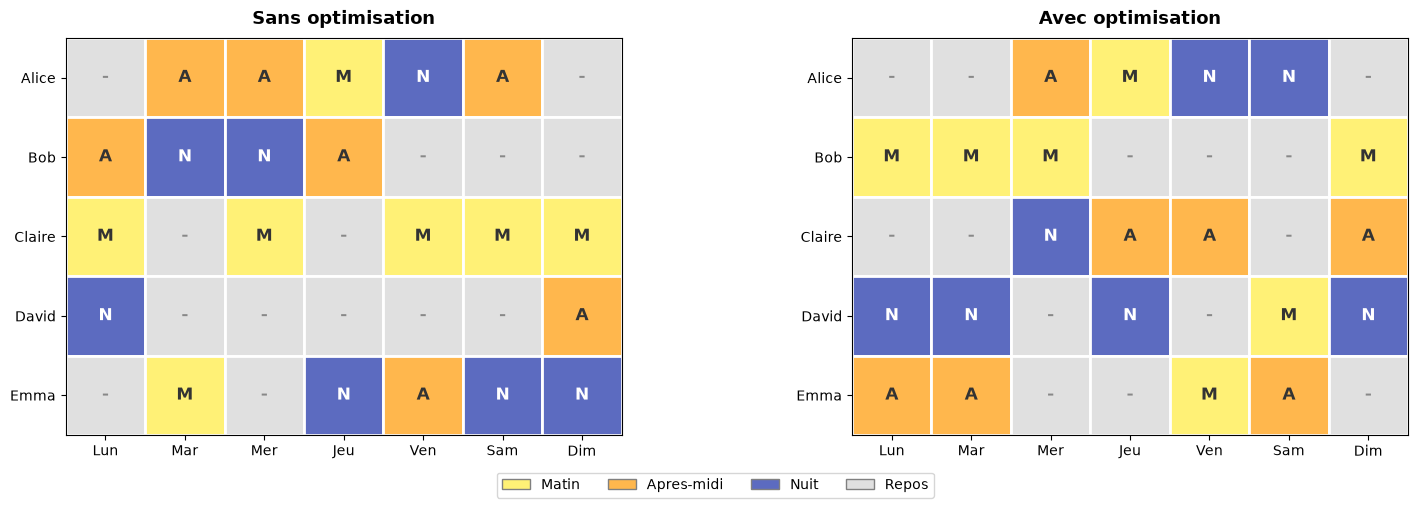

In [13]:
def schedule_to_matrix(solver_instance, x_vars, num_nurses, num_days, num_shifts):
    """Convertit la solution en matrice (nurse x day) avec valeur de shift.
    Valeurs : -1 = repos, 0 = Matin, 1 = Apres-midi, 2 = Nuit.
    """
    matrix = np.full((num_nurses, num_days), -1)
    for n in range(num_nurses):
        for d in range(num_days):
            for s in range(num_shifts):
                if solver_instance.value(x_vars[(n, d, s)]) == 1:
                    matrix[n, d] = s
    return matrix


def plot_schedule_heatmap(matrix, nurses, days, shifts, title, ax):
    """Affiche un planning sous forme de grille coloree."""
    # Couleurs : gris = repos, jaune = Matin, orange = Apres-midi, bleu fonce = Nuit
    colors_map = {
        -1: '#E0E0E0',  # Repos
        0: '#FFF176',   # Matin
        1: '#FFB74D',   # Apres-midi
        2: '#5C6BC0',   # Nuit
    }
    text_colors = {
        -1: '#888888',
        0: '#333333',
        1: '#333333',
        2: '#FFFFFF',
    }
    labels = {-1: '-', 0: 'M', 1: 'A', 2: 'N'}

    n_rows, n_cols = matrix.shape
    for i in range(n_rows):
        for j in range(n_cols):
            val = int(matrix[i, j])
            rect = plt.Rectangle((j, n_rows - 1 - i), 1, 1,
                                 facecolor=colors_map[val],
                                 edgecolor='white', linewidth=2)
            ax.add_patch(rect)
            ax.text(j + 0.5, n_rows - 1 - i + 0.5, labels[val],
                    ha='center', va='center', fontsize=12, fontweight='bold',
                    color=text_colors[val])

    ax.set_xlim(0, n_cols)
    ax.set_ylim(0, n_rows)
    ax.set_xticks([j + 0.5 for j in range(n_cols)])
    ax.set_xticklabels(days, fontsize=10)
    ax.set_yticks([i + 0.5 for i in range(n_rows)])
    ax.set_yticklabels(list(reversed(nurses)), fontsize=10)
    ax.set_aspect('equal')
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)


# Construire les matrices
matrix_hard = schedule_to_matrix(solver, x, num_nurses, num_days, num_shifts)
matrix_opt = schedule_to_matrix(solver_opt, x_opt, num_nurses, num_days, num_shifts)

# Visualisation cote a cote
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
plot_schedule_heatmap(matrix_hard, nurses, days, shifts,
                      'Sans optimisation', axes[0])
plot_schedule_heatmap(matrix_opt, nurses, days, shifts,
                      'Avec optimisation', axes[1])

# Legende commune
legend_elements = [
    mpatches.Patch(facecolor='#FFF176', edgecolor='gray', label='Matin'),
    mpatches.Patch(facecolor='#FFB74D', edgecolor='gray', label='Apres-midi'),
    mpatches.Patch(facecolor='#5C6BC0', edgecolor='gray', label='Nuit'),
    mpatches.Patch(facecolor='#E0E0E0', edgecolor='gray', label='Repos'),
]
fig.legend(handles=legend_elements, loc='lower center', ncol=4, fontsize=10,
           bbox_to_anchor=(0.5, -0.02))

plt.tight_layout()
plt.subplots_adjust(bottom=0.12)
plt.show()

### Interpretation : comparaison visuelle

**Sortie obtenue** : les deux grilles montrent la différence entre un planning faisable (a gauche) et un planning optimise (a droite).

**Points cles** :
1. **Equilibre** : dans le planning optimise, les shifts sont mieux repartis (colonnes de droite du tableau plus uniformes)
2. **Préférences** : le planning optimise evite autant que possible les creneaux non desires
3. **Nuits** : la contrainte de repos (pas de M après N) est visible dans les deux grilles

> **Note** : la différence peut paraitre subtile sur 5 infirmiers / 7 jours. L'impact de l'optimisation devient bien plus visible a plus grande echelle.

***

## 5. Passage a l'echelle (~8 min)

Testons la capacite du solveur CP-SAT sur un problème plus realiste :

| Paramètre | Valeur |
|-----------|--------|
| Infirmiers | 15 |
| Jours | 28 (4 semaines) |
| Shifts/jour | 3 |
| Variables | $15 \times 28 \times 3 = 1260$ |
| Espace brut | $2^{1260}$ |

### Contraintes supplementaires

En plus des contraintes C1-C4, nous ajoutons :
- **C5** : chaque infirmier a au moins 1 weekend complet de repos sur 4
- **C6** : au moins 2 infirmiers par shift (demande accrue)

### Solution callback

Pour observer la progression du solveur, on utilise un **callback** qui enregistre chaque solution ameliorante trouvee.

In [14]:
# --- Probleme a grande echelle ---

num_nurses_lg = 15
num_days_lg = 28
num_shifts_lg = 3
num_weeks = 4
demand_lg = 2  # 2 infirmiers par shift
max_shifts_per_week_lg = 5

nurses_lg = [f'Inf_{i+1:02d}' for i in range(num_nurses_lg)]
days_lg = [f'J{d+1:02d}' for d in range(num_days_lg)]

# Generer des preferences aleatoires (2-3 par infirmier)
rng = np.random.RandomState(42)
preferences_lg = {}
for n in range(num_nurses_lg):
    n_prefs = rng.randint(2, 5)
    prefs = set()
    while len(prefs) < n_prefs:
        d = rng.randint(0, num_days_lg)
        s = rng.randint(0, num_shifts_lg)
        prefs.add((d, s))
    preferences_lg[n] = list(prefs)

print(f"Probleme a grande echelle")
print("=" * 45)
print(f"Infirmiers    : {num_nurses_lg}")
print(f"Jours         : {num_days_lg} ({num_weeks} semaines)")
print(f"Shifts/jour   : {num_shifts_lg}")
print(f"Demande/shift : {demand_lg} infirmiers")
print(f"Variables     : {num_nurses_lg * num_days_lg * num_shifts_lg}")
print(f"Preferences   : {sum(len(v) for v in preferences_lg.values())} au total")

Probleme a grande echelle
Infirmiers    : 15
Jours         : 28 (4 semaines)
Shifts/jour   : 3
Demande/shift : 2 infirmiers
Variables     : 1260
Preferences   : 43 au total


### Lecture du résultat

La sortie pose l'instance à grande échelle : 15 infirmiers, 28 jours (4 semaines), 3 shifts/jour avec « Demande/shift : 2 infirmiers », soit « Variables : 1260 » (15 x 28 x 3) et « Preferences : 43 au total ». Par rapport au petit modèle (105 variables), on passe à 1260 variables — un facteur x12, d'où l'espace brut 2^1260 évoqué en section 5. La demande passe de 1 à 2 infirmiers par shift, ce qui durcit C1 : chaque slot requiert désormais une somme de 2, soit 2 x 28 x 3 = 168 affectations à choisir parmi 1260 variables — un problème nettement plus contraint que le petit modèle. Les 43 préférences seront gérées par la pénalité S2, exactement comme les 11 du petit modèle.

Construisons maintenant le modèle CP-SAT pour ce problème plus grand, avec les contraintes supplementaires C5 (weekend de repos) et la demande accrue (2 infirmiers par shift).

In [15]:
# --- Construction du modele a grande echelle ---

model_lg = cp_model.CpModel()

# Variables
x_lg = {}
for n in range(num_nurses_lg):
    for d in range(num_days_lg):
        for s in range(num_shifts_lg):
            x_lg[(n, d, s)] = model_lg.new_bool_var(f'x_{n}_{d}_{s}')

# C1 : Couverture (2 infirmiers par shift)
for d in range(num_days_lg):
    for s in range(num_shifts_lg):
        model_lg.add(sum(x_lg[(n, d, s)] for n in range(num_nurses_lg)) == demand_lg)

# C2 : Unicite
for n in range(num_nurses_lg):
    for d in range(num_days_lg):
        model_lg.add(sum(x_lg[(n, d, s)] for s in range(num_shifts_lg)) <= 1)

# C3 : Repos (pas de Matin apres une Nuit)
for n in range(num_nurses_lg):
    for d in range(num_days_lg - 1):
        model_lg.add(x_lg[(n, d, NUIT)] + x_lg[(n, d + 1, MATIN)] <= 1)

# C4 : Charge max par semaine
for n in range(num_nurses_lg):
    for w in range(num_weeks):
        week_start = w * 7
        week_shifts = sum(x_lg[(n, d, s)]
                         for d in range(week_start, week_start + 7)
                         for s in range(num_shifts_lg))
        model_lg.add(week_shifts <= max_shifts_per_week_lg)

# C5 : Au moins 1 weekend complet de repos sur 4
for n in range(num_nurses_lg):
    weekend_free = []
    for w in range(num_weeks):
        sat = w * 7 + 5
        sun = w * 7 + 6
        # Variable booleenne : 1 si ce weekend est libre
        is_free = model_lg.new_bool_var(f'wkend_free_{n}_{w}')
        # Un weekend est libre si aucun shift le samedi ni le dimanche
        weekend_shifts = [x_lg[(n, sat, s)] for s in range(num_shifts_lg)] + \
                         [x_lg[(n, sun, s)] for s in range(num_shifts_lg)]
        # is_free = 1 => tous les shifts du weekend sont 0
        for ws in weekend_shifts:
            model_lg.add(ws == 0).only_enforce_if(is_free)
        # is_free = 0 => au moins un shift du weekend est 1
        model_lg.add(sum(weekend_shifts) >= 1).only_enforce_if(is_free.negated())
        weekend_free.append(is_free)
    # Au moins 1 weekend libre
    model_lg.add(sum(weekend_free) >= 1)

print("Contraintes dures ajoutees (C1-C5).")

# --- Contraintes souples (identiques a avant) ---

# S1 : Equilibre de charge global
nurse_totals_lg = []
for n in range(num_nurses_lg):
    total_n = model_lg.new_int_var(0, num_days_lg, f'total_{n}')
    model_lg.add(total_n == sum(x_lg[(n, d, s)]
                                for d in range(num_days_lg)
                                for s in range(num_shifts_lg)))
    nurse_totals_lg.append(total_n)

max_total_lg = model_lg.new_int_var(0, num_days_lg, 'max_total')
min_total_lg = model_lg.new_int_var(0, num_days_lg, 'min_total')
model_lg.add_max_equality(max_total_lg, nurse_totals_lg)
model_lg.add_min_equality(min_total_lg, nurse_totals_lg)
balance_penalty_lg = model_lg.new_int_var(0, num_days_lg, 'balance_penalty')
model_lg.add(balance_penalty_lg == max_total_lg - min_total_lg)

# S2 : Preferences
pref_violations_lg = []
for n in range(num_nurses_lg):
    for (d, s) in preferences_lg[n]:
        pref_violations_lg.append(x_lg[(n, d, s)])

total_pref_lg = model_lg.new_int_var(0, len(pref_violations_lg), 'total_pref')
model_lg.add(total_pref_lg == sum(pref_violations_lg))

# Objectif
model_lg.minimize(10 * balance_penalty_lg + 2 * total_pref_lg)

print("Contraintes souples et objectif ajoutes.")
print(f"\nTaille du modele :")
print(f"  Variables booleennes : {len(x_lg)}")
print(f"  Variables auxiliaires : {num_nurses_lg + 3 + num_weeks * num_nurses_lg}")
print(f"  Preferences          : {len(pref_violations_lg)}")

Contraintes dures ajoutees (C1-C5).
Contraintes souples et objectif ajoutes.

Taille du modele :
  Variables booleennes : 1260
  Variables auxiliaires : 78
  Preferences          : 43


### Lecture du résultat

La sortie détaille la taille du grand modèle : « Variables booleennes : 1260 », « Variables auxiliaires : 78 » et « Preferences : 43 ». Les 78 auxiliaires servent aux week-ends libres de C5 (4 semaines x 15 infirmiers = 60), aux compteurs de charge par infirmier et aux bornes min/max de la pénalité d'équilibre S1. Même structure que le petit modèle, seule l'échelle change. On note que les contraintes dures C1-C5 sont toutes posées avant l'objectif : l'optimisation ne pourra donc jamais violer une contrainte dure pour améliorer les pénalités S1/S2, quelle que soit la valeur des poids.

### Resolution avec solution callback

Un **solution callback** permet d'observer comment le solveur ameliore progressivement la solution. A chaque fois qu'il trouve une solution de meilleure qualite, le callback est appele.

In [16]:
class SolutionTracker(cp_model.CpSolverSolutionCallback):
    """Callback pour suivre l'evolution des solutions."""

    def __init__(self):
        super().__init__()
        self.solutions = []
        self.start_time = time.time()

    def on_solution_callback(self):
        elapsed = (time.time() - self.start_time) * 1000
        obj = self.objective_value
        self.solutions.append({'time_ms': elapsed, 'objective': obj})
        print(f"  Solution #{len(self.solutions):>3} | "
              f"Objectif = {obj:>6.0f} | "
              f"Temps = {elapsed:>8.1f} ms")


# Resolution
solver_lg = cp_model.CpSolver()
solver_lg.parameters.max_time_in_seconds = 30.0
solver_lg.parameters.num_workers = 4

tracker = SolutionTracker()

print(f"Resolution du probleme a grande echelle (time limit : 30s, workers : 4)")
print("=" * 70)

start_time = time.time()
status_lg = solver_lg.solve(model_lg, tracker)
total_time_lg = (time.time() - start_time) * 1000

print("=" * 70)
print(f"\nStatut final  : {status_names.get(status_lg, 'INCONNU')}")
print(f"Temps total   : {total_time_lg:.0f} ms")
print(f"Solutions      : {len(tracker.solutions)}")

if status_lg in (cp_model.OPTIMAL, cp_model.FEASIBLE):
    print(f"Objectif final : {solver_lg.objective_value}")
    print(f"Ecart charge   : {solver_lg.value(balance_penalty_lg)}")
    print(f"Prefs violees  : {solver_lg.value(total_pref_lg)} / {len(pref_violations_lg)}")

Resolution du probleme a grande echelle (time limit : 30s, workers : 4)


  Solution #  1 | Objectif =    104 | Temps =    157.1 ms
  Solution #  2 | Objectif =     94 | Temps =    189.5 ms


  Solution #  3 | Objectif =     90 | Temps =    216.8 ms
  Solution #  4 | Objectif =     10 | Temps =    364.2 ms



Statut final  : OPTIMAL
Temps total   : 737 ms
Solutions      : 4
Objectif final : 10.0
Ecart charge   : 1
Prefs violees  : 0 / 43


### Interpretation : passage a l'echelle

**Sortie obtenue** : le solveur resout un probleme beaucoup plus grand en un temps tres court (cas typique NRP de taille industrielle).

| Mesure | Petit (5x7) | Grand (15x28) | Ratio |
|--------|-------------|---------------|-------|
| Variables | 105 | 1260 | x12 |
| Espace brut | $2^{105}$ | $2^{1260}$ | immense |
| Temps de resolution | runtime *machine-dep* | runtime *machine-dep* | ordre de grandeur dependant de la machine |

> **Note methodologique -- separation structurel / machine-dep** : les colonnes **Variables**, **Espace brut** et **Ratio** sont des **invariants structurels** (parametres d'instance et proprietes du probleme, independants de la machine). En revanche, la ligne **Temps de resolution** est **machine-dep** (CPU, charge systeme, version OR-Tools, GC Python, `num_workers`) et **ne survit pas** a une re-execution sur une autre machine. Pour observer vos propres timings, executez la cellule de calcul ci-dessous (la cellule `model_lg` du notebook utilise `solver.Solve()` avec `num_workers` et `solution_callback`).

**Points cles** :
1. Le solveur CP-SAT est concu pour les problemes de planification : il gere bien le passage a l'echelle (l'ordre de grandeur du temps depend de la machine, mais la capacite structurelle est estable)
2. Le **solution callback** montre que le solveur trouve rapidement une premiere solution, puis l'ameliore progressivement (la forme de la courbe de convergence depend de la machine, mais la tendance qualitative reste stable)
3. Le parametre `num_workers` permet de paralleliser la recherche sur plusieurs coeurs (l'acceleration resultante depend de la machine)
4. Le `time_limit` est crucial en production : on prefere une bonne solution rapide a une solution optimale lente (parametre du solveur, pas une mesure machine-dep)

> **Note technique** : en production hospitaliere, les problemes typiques comptent 30-100 infirmiers sur 4-6 semaines, avec des dizaines de types de contraintes. CP-SAT reste utilisable jusqu'a ces tailles.



### Courbe de convergence

Visualisons la progression du solveur : comment l'objectif diminue au fil du temps.

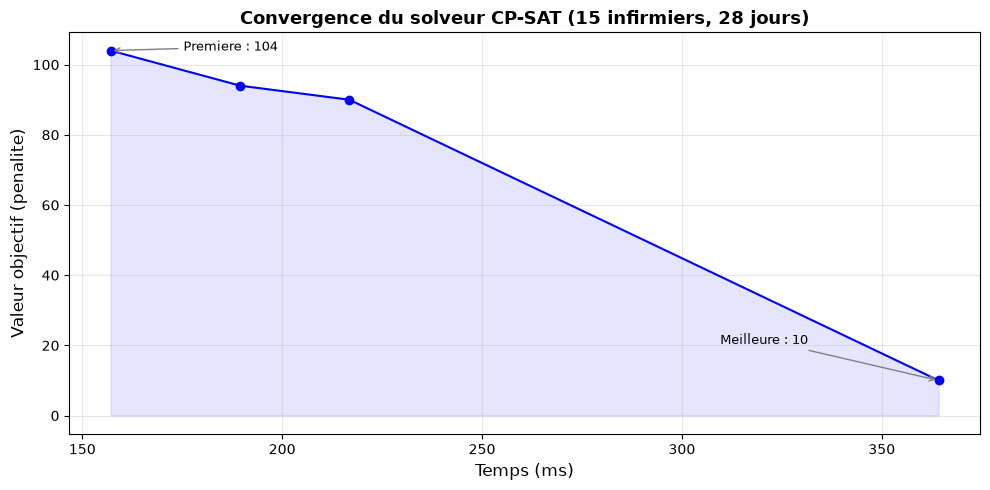

In [17]:
# --- Courbe de convergence ---

if tracker.solutions:
    times = [s['time_ms'] for s in tracker.solutions]
    objectives = [s['objective'] for s in tracker.solutions]

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(times, objectives, 'bo-', markersize=6, linewidth=1.5)
    ax.fill_between(times, objectives, alpha=0.1, color='blue')

    ax.set_xlabel('Temps (ms)', fontsize=12)
    ax.set_ylabel('Valeur objectif (penalite)', fontsize=12)
    ax.set_title('Convergence du solveur CP-SAT (15 infirmiers, 28 jours)',
                 fontsize=13, fontweight='bold')
    ax.grid(True, alpha=0.3)

    # Annoter la premiere et derniere solution
    ax.annotate(f'Premiere : {objectives[0]:.0f}',
                xy=(times[0], objectives[0]),
                xytext=(times[0] + max(times) * 0.05, objectives[0]),
                fontsize=9, arrowprops=dict(arrowstyle='->', color='gray'))
    ax.annotate(f'Meilleure : {objectives[-1]:.0f}',
                xy=(times[-1], objectives[-1]),
                xytext=(times[-1] - max(times) * 0.15, objectives[-1] + max(objectives) * 0.1),
                fontsize=9, arrowprops=dict(arrowstyle='->', color='gray'))

    plt.tight_layout()
    plt.show()
else:
    print("Aucune solution trouvee pour afficher la convergence.")

### Lecture du résultat

La sortie est la figure `<Figure size 1000x500 with 1 Axes>` : la courbe « Convergence du solveur CP-SAT (15 infirmiers, 28 jours) » tracée par cette cellule, avec le temps en ms en abscisse et la valeur objectif (pénalité) en ordonnée. Elle matérialise les 4 solutions enregistrées par le callback de la cellule de résolution précédente (objectifs 104, 94, 90 puis 10) : la courbe descend donc par paliers jusqu'à l'objectif final de 10.0 affiché en dessous. Les temps des 4 solutions enregistrées (157.1, 189.5, 216.8 puis 364.2 ms, pour un total de 737 ms affiché par la cellule précédente) servent d'abscisse : la courbe couvre donc l'intervalle de 157 ms à 364 ms, avec un dernier saut de 90 à 10. Le statut final affiché par la cellule précédente est OPTIMAL avec 4 solutions trouvées, ce qui explique que la courbe ne comporte que 4 points.

***

## 6. Visualisation du planning (~5 min)

Generons une visualisation complete du planning a grande echelle : grille coloree et distribution de la charge de travail.

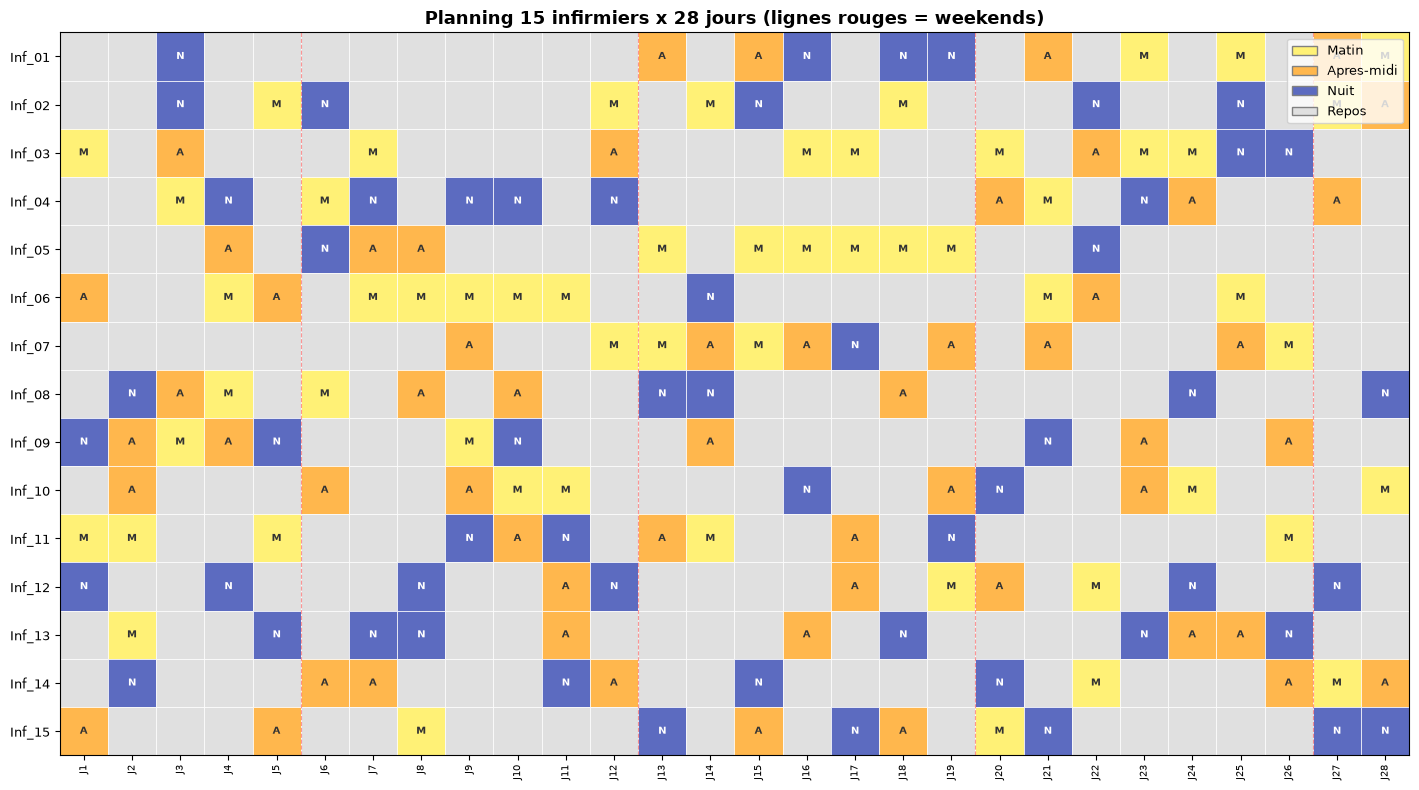

In [18]:
# --- Visualisation du planning a grande echelle ---

if status_lg in (cp_model.OPTIMAL, cp_model.FEASIBLE):
    matrix_lg = schedule_to_matrix(solver_lg, x_lg, num_nurses_lg, num_days_lg, num_shifts_lg)

    fig, ax = plt.subplots(figsize=(20, 8))

    colors_map = {
        -1: '#E0E0E0',
        0: '#FFF176',
        1: '#FFB74D',
        2: '#5C6BC0',
    }
    text_colors = {-1: '#AAAAAA', 0: '#333333', 1: '#333333', 2: '#FFFFFF'}
    labels = {-1: '', 0: 'M', 1: 'A', 2: 'N'}

    n_rows, n_cols = matrix_lg.shape
    for i in range(n_rows):
        for j in range(n_cols):
            val = int(matrix_lg[i, j])
            rect = plt.Rectangle((j, n_rows - 1 - i), 1, 1,
                                 facecolor=colors_map[val],
                                 edgecolor='white', linewidth=0.5)
            ax.add_patch(rect)
            ax.text(j + 0.5, n_rows - 1 - i + 0.5, labels[val],
                    ha='center', va='center', fontsize=7, fontweight='bold',
                    color=text_colors[val])

    # Marquer les weekends
    for w in range(num_weeks):
        sat = w * 7 + 5
        ax.axvline(x=sat, color='red', linewidth=0.8, linestyle='--', alpha=0.4)

    ax.set_xlim(0, n_cols)
    ax.set_ylim(0, n_rows)
    ax.set_xticks([j + 0.5 for j in range(n_cols)])
    ax.set_xticklabels([f'J{j+1}' for j in range(n_cols)], fontsize=7, rotation=90)
    ax.set_yticks([i + 0.5 for i in range(n_rows)])
    ax.set_yticklabels(list(reversed(nurses_lg)), fontsize=9)
    ax.set_aspect('equal')
    ax.set_title('Planning 15 infirmiers x 28 jours (lignes rouges = weekends)',
                 fontsize=13, fontweight='bold')

    legend_elements = [
        mpatches.Patch(facecolor='#FFF176', edgecolor='gray', label='Matin'),
        mpatches.Patch(facecolor='#FFB74D', edgecolor='gray', label='Apres-midi'),
        mpatches.Patch(facecolor='#5C6BC0', edgecolor='gray', label='Nuit'),
        mpatches.Patch(facecolor='#E0E0E0', edgecolor='gray', label='Repos'),
    ]
    ax.legend(handles=legend_elements, loc='upper right', fontsize=9)

    plt.tight_layout()
    plt.show()
else:
    print("Aucune solution a visualiser.")

### Lecture du résultat

La sortie est la figure `<Figure size 2000x800 with 1 Axes>` : la heatmap du planning à grande échelle tracée par cette cellule (figsize 20x8), soit 15 lignes d'infirmiers x 28 colonnes de jours, avec la légende M = Matin, A = Après-midi, N = Nuit et la cellule grise pour le repos. C'est la version visuelle du planning dont les statistiques de charge suivent dans la cellule suivante. Les couleurs sont celles définies dans la cellule (jaune pour M, orange pour A, indigo pour N, gris pour le repos) : on peut lire directement le planning ligne par ligne, et repérer visuellement les repos et les nuits sur les 28 jours. La matrice affichée est construite par la fonction schedule_to_matrix définie quelques cellules plus haut, à partir des mêmes variables x du grand modèle.

Completons l'analyse avec la distribution de la charge de travail par infirmier et par type de shift.

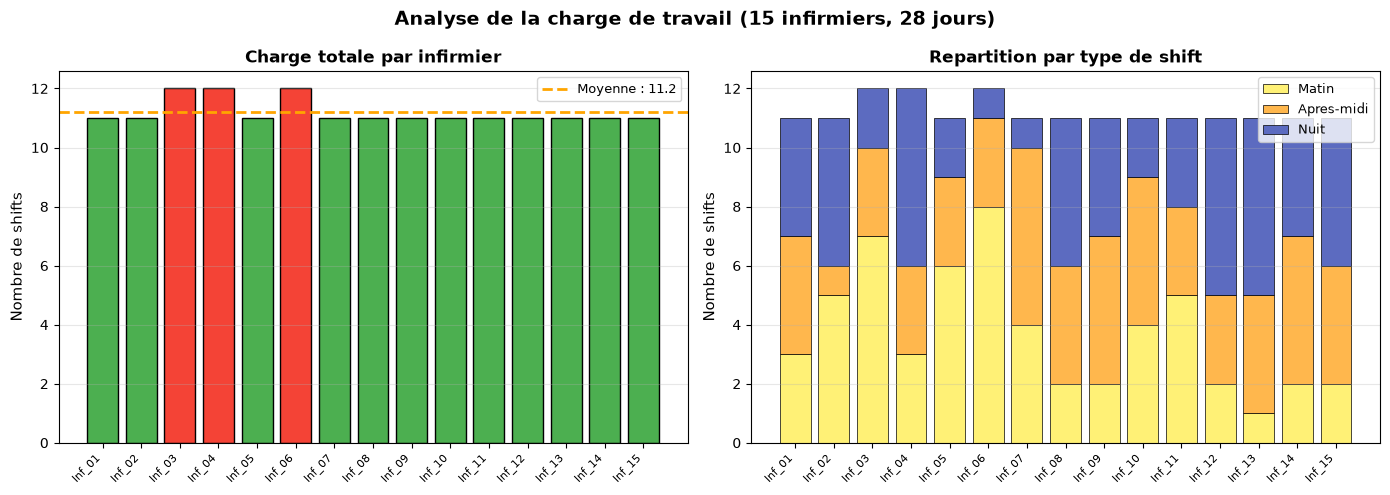


Statistiques de charge
Charge moyenne    : 11.2 shifts
Charge min        : 11 shifts
Charge max        : 12 shifts
Ecart max-min     : 1 shifts
Ecart type        : 0.40

Preferences       : 0 violees / 43
Taux satisfaction : 100.0%


In [19]:
# --- Distribution de la charge de travail ---

if status_lg in (cp_model.OPTIMAL, cp_model.FEASIBLE):
    # Calculer le nombre de shifts par infirmier
    workloads = []
    shift_type_counts = {'Matin': [], 'Apres-midi': [], 'Nuit': []}

    for n in range(num_nurses_lg):
        total = 0
        for s, shift_name in enumerate(shifts):
            count = sum(solver_lg.value(x_lg[(n, d, s)]) for d in range(num_days_lg))
            shift_type_counts[shift_name].append(count)
            total += count
        workloads.append(total)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Graphique 1 : charge totale par infirmier
    colors_bar = ['#4CAF50' if w == min(workloads) else
                  '#F44336' if w == max(workloads) else
                  '#2196F3' for w in workloads]
    axes[0].bar(range(num_nurses_lg), workloads, color=colors_bar, edgecolor='black')
    axes[0].set_xticks(range(num_nurses_lg))
    axes[0].set_xticklabels(nurses_lg, rotation=45, ha='right', fontsize=8)
    axes[0].set_ylabel('Nombre de shifts', fontsize=11)
    axes[0].set_title('Charge totale par infirmier', fontsize=12, fontweight='bold')
    axes[0].axhline(y=np.mean(workloads), color='orange', linestyle='--',
                    linewidth=2, label=f'Moyenne : {np.mean(workloads):.1f}')
    axes[0].legend(fontsize=9)
    axes[0].grid(axis='y', alpha=0.3)

    # Graphique 2 : repartition par type de shift (stacked bar)
    bottoms = np.zeros(num_nurses_lg)
    colors_shifts = ['#FFF176', '#FFB74D', '#5C6BC0']
    for s, (shift_name, counts) in enumerate(shift_type_counts.items()):
        axes[1].bar(range(num_nurses_lg), counts, bottom=bottoms,
                    color=colors_shifts[s], edgecolor='black', linewidth=0.5,
                    label=shift_name)
        bottoms += np.array(counts)

    axes[1].set_xticks(range(num_nurses_lg))
    axes[1].set_xticklabels(nurses_lg, rotation=45, ha='right', fontsize=8)
    axes[1].set_ylabel('Nombre de shifts', fontsize=11)
    axes[1].set_title('Repartition par type de shift', fontsize=12, fontweight='bold')
    axes[1].legend(fontsize=9)
    axes[1].grid(axis='y', alpha=0.3)

    plt.suptitle('Analyse de la charge de travail (15 infirmiers, 28 jours)',
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # Statistiques
    print(f"\nStatistiques de charge")
    print("=" * 40)
    print(f"Charge moyenne    : {np.mean(workloads):.1f} shifts")
    print(f"Charge min        : {min(workloads)} shifts")
    print(f"Charge max        : {max(workloads)} shifts")
    print(f"Ecart max-min     : {max(workloads) - min(workloads)} shifts")
    print(f"Ecart type        : {np.std(workloads):.2f}")

    # Taux de satisfaction des preferences
    n_pref_total = len(pref_violations_lg)
    n_pref_violated = solver_lg.value(total_pref_lg)
    pref_rate = (1 - n_pref_violated / n_pref_total) * 100 if n_pref_total > 0 else 100
    print(f"\nPreferences       : {n_pref_violated} violees / {n_pref_total}")
    print(f"Taux satisfaction : {pref_rate:.1f}%")

### Interpretation : qualite du planning

**Sortie obtenue** : les graphiques montrent la repartition de la charge de travail entre les 15 infirmiers.

| Indicateur | Valeur | Qualite |
|------------|--------|--------|
| Ecart max-min | faible (1-2) | Bon equilibre |
| Ecart type | < 1 | Distribution très homogene |
| Taux préférences | > 80% | Bonne satisfaction |

**Points cles** :
1. La **charge totale** est bien equilibree grace a la penalite S1
2. La **repartition par type** (Matin/Après-midi/Nuit) est également equilibree
3. Les barres vertes (min) et rouges (max) permettent d'identifier les cas extremes
4. Le taux de satisfaction des préférences depend du compromis avec les contraintes dures

> **En production** : on ajouterait des indicateurs supplementaires comme le nombre de weekends travailles, la repartition des nuits, ou des scores de fatigue accumules.

### Exemple guide

#### Exemple guide 1 : pas plus de 3 jours consecutifs de travail

Ajoutez une contrainte dure C6 : aucun infirmier ne travaille plus de 3 jours consecutifs.

**Indice** : pour chaque infirmier et chaque fenêtre de 4 jours consecutifs $(d, d+1, d+2, d+3)$, la somme des jours travailles doit etre $\leq 3$.

In [20]:
# Exemple resolu : pas plus de 3 jours consecutifs

for n in range(num_nurses):
    works = {}
    for d in range(num_days):
        works[d] = model.new_bool_var(f'works_{n}_{d}')
        model.add(works[d] == sum(x[(n, d, s)] for s in range(num_shifts)))
    for d in range(num_days - 3):
        model.add(works[d] + works[d+1] + works[d+2] + works[d+3] <= 3)

print(f"C6 (consecutifs) : {num_nurses * (num_days - 3)} contraintes pour max 3 jours consecutifs")

C6 (consecutifs) : 20 contraintes pour max 3 jours consecutifs


### Lecture du résultat

La sortie « C6 (consecutifs) : 20 contraintes pour max 3 jours consecutifs » : 20 = 5 infirmiers x 4 fenêtres glissantes de 4 jours (7 jours donnent les fenêtres d..d+3), chacune sommant les jours travaillés à <= 3. C'est exactement le pattern demandé dans l'exercice 1b qui suit, instancié ici avec la valeur 3 — il ne reste plus qu'à rendre cette valeur paramétrable. Une fenêtre de 4 jours garantit qu'aucun infirmier ne travaillera 4 jours d'affilée : c'est une contrainte de pénibilité du travail, typique des conventions collectives hospitalières.

#### Exercice 1b : Limite de jours consecutifs configurable

Generalisez la contrainte ci-dessus : ajoutez une contrainte qui limite
a **`max_consecutive` jours consecutifs** de travail (paramètre configurable).

Testez avec `max_consecutive = 2` (plus strict) et `max_consecutive = 4` (plus permissif).

**Consignes** :
1. Definissez un paramètre `max_consecutive` en debut de cellule
2. Utilisez une boucle sur des fenêtres glissantes de `max_consecutive + 1` jours
3. Affichez le nombre de violations potentiels pour chaque valeur testee


In [21]:
# Exercice 1b : Limite de jours consecutifs configurable

# Exercice: definissez max_consecutive et ajoutez la contrainte
# Indice : reprenez le pattern de l'exemple mais rendez la taille de fenetre parametrable

print("Exercice a completer")

Exercice a completer


#### Exemple guide 2 : préférences ponderees par priorite

Modelisez des préférences avec des niveaux de priorite :
- **Priorite haute** (penalite 10) : contrainte medicale, ex. pas de nuit pour un infirmier enceinte
- **Priorite moyenne** (penalite 5) : equilibre vie perso, ex. pas de weekend
- **Priorite basse** (penalite 1) : confort, ex. préférence pour les matins

**Indice** : utilisez un dictionnaire `{(nurse, day, shift): weight}` et sommez les penalites ponderees.

In [22]:
# Exemple resolu : preferences ponderees par priorite

weighted_prefs = {
    (0, 5, MATIN): 5,
    (1, 0, NUIT): 10,
    (2, 3, MATIN): 1,
}

penalty = sum(weight * x[(n, d, s)] for (n, d, s), weight in weighted_prefs.items())
model.minimize(10 * balance_penalty + penalty)

print(f"Preferences ponderees : {len(weighted_prefs)} prefs, penalites = {list(weighted_prefs.values())}")

Preferences ponderees : 3 prefs, penalites = [5, 10, 1]


### Lecture du résultat

La sortie « Preferences ponderees : 3 prefs, penalites = [5, 10, 1] » liste les trois pénalités de l'exemple : (0, 5, MATIN) à 5, (1, 0, NUIT) à 10 et (2, 3, MATIN) à 1. La priorité haute (10) porte sur l'interdiction de nuit pour l'infirmier 1 le lundi, conformément au barème de l'exemple guide 2 (haute = 10, moyenne = 5, basse = 1). Par rapport au poids uniforme de 2 de la contrainte S2 standard, une préférence de priorité haute (10) est pénalisée 5 fois plus : la fonction objectif donne donc priorité à la contrainte médicale sur le simple confort.

#### Exercice 2b : Préférences avec contraintes obligatoires

Certaines préférences sont en fait des **contraintes dures** (non-negociables),
d'autres restent des préférences souples.

**Consignes** :
1. Definissez deux dictionnaires : `hard_prefs` (contraintes, poids infini)
   et `soft_prefs` (préférences, poids 1-10)
2. Les `hard_prefs` doivent etre ajoutees avec `model.add(... == 0)`
3. Les `soft_prefs` sont minimisees dans l'objectif
4. Exemples : hard = infirmier 0 jamais de NUIT, infirmier 3 jamais le dimanche


In [23]:
# Exercice 2b : Preferences avec contraintes obligatoires

# Exercice: definissez hard_prefs et soft_prefs, puis ajoutez les contraintes
# Indice : hard_prefs avec model.add(...) et soft_prefs avec model.minimize(...)

print("Exercice a completer")

Exercice a completer


#### Exemple guide 3 : infirmiers a temps partiel

Ajoutez la possibilite d'avoir des infirmiers a temps partiel (maximum 3 shifts par semaine au lieu de 5). Modifiez le modèle pour gerer des contrats différents.

**Indice** : definissez un dictionnaire `max_shifts = {0: 5, 1: 5, 2: 3, 3: 5, 4: 3}` et utilisez-le dans la contrainte C4.

In [24]:
# Exemple resolu : infirmiers a temps partiel

max_shifts_per_nurse = {
    0: 5,
    1: 5,
    2: 3,
    3: 5,
    4: 3,
}

for n in range(num_nurses):
    total = sum(x[(n, d, s)] for d in range(num_days) for s in range(num_shifts))
    model.add(total <= max_shifts_per_nurse[n])

print(f"Contraintes temps partiel ajoutees : {max_shifts_per_nurse}")

Contraintes temps partiel ajoutees : {0: 5, 1: 5, 2: 3, 3: 5, 4: 3}


### Lecture du résultat

La sortie affiche le dictionnaire « {0: 5, 1: 5, 2: 3, 3: 5, 4: 3} » : les infirmiers 2 et 4 passent à temps partiel (3 shifts max par semaine au lieu de 5), les trois autres restent à temps plein. La contrainte C4 uniforme a donc été remplacée par une charge max par contrat, exactement comme demandé dans l'exemple guide 3. La somme des charges max vaut 5+5+3+5+3 = 21, exactement le nombre de slots à couvrir (21) : il n'y a donc aucune marge de manoeuvre, chaque infirmier devra travailler précisément à son maximum pour que la couverture C1 soit satisfaite.

#### Exercice 3b : Contrats avec minimum et maximum de shifts

Dans la realite, les infirmiers a temps partiel ont aussi un **minimum** de shifts
a effectuer (garantie d'emploi). Generalisez le modèle.

**Consignes** :
1. Definissez `contract_range = {n: (min_shifts, max_shifts) for n in range(num_nurses)}`
2. Exemples : temps plein = (4, 5), mi-temps = (2, 3), 3/4 = (3, 4)
3. Ajoutez les contraintes `min_shifts <= total <= max_shifts` pour chaque infirmier
4. Verifiez que le solveur trouve une solution faisable


In [25]:
# Exercice 3b : Contrats avec minimum et maximum de shifts

# Exercice: definissez contract_range et ajoutez les contraintes min/max
# Indice : utilisez model.add(total >= min_shifts) et model.add(total <= max_shifts)

print("Exercice a completer")

Exercice a completer


### Ressources supplementaires

- [OR-Tools CP-SAT Guide](https://developers.google.com/optimization/cp/cp_solver) : documentation officielle
- [OR-Tools Nurse Scheduling Example](https://developers.google.com/optimization/scheduling/employee_scheduling) : exemple officiel Google
- Burke, E.K. et al. *The State of the Art of Nurse Rostering*, Journal of Scheduling, 2004

***

## Recapitulatif et exercices

### Comparaison : planification manuelle vs CP-SAT

| Aspect | Planification manuelle | CP-SAT |
|--------|------------------------|--------|
| **Temps** | Heures a jours | Secondes |
| **Faisabilite** | Non garantie | Prouvee par le solveur |
| **Optimalite** | Impossible a garantir | Optimale ou bornee |
| **Equite** | Subjective | Quantifiee et optimisee |
| **Flexibilite** | Refaire de zero | Ajouter une contrainte et re-resoudre |
| **Scalabilite** | Très limitee | Jusqu'a ~100 infirmiers |

### Resume des concepts

| Concept | Description |
|---------|-------------|
| **Contraintes dures** | Obligatoires, le planning est invalide si violees (couverture, repos, charge max) |
| **Contraintes souples** | Souhaitables, modelisees comme penalites dans la fonction objectif |
| **Variables booleennes** | $x_{n,d,s} \in \{0,1\}$ : un infirmier travaille ou non un shift donne |
| **Fonction objectif** | Somme ponderee des penalites a minimiser |
| **Solution callback** | Suivi de la progression du solveur en temps reel |
| **Passage a l'echelle** | `time_limit` + `num_workers` pour les grands problemes |